In [1]:
!pip install ucimlrepo -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

cdc_diabetes_health_indicators = fetch_ucirepo(id=891)

X = cdc_diabetes_health_indicators.data.features
y = cdc_diabetes_health_indicators.data.targets

df = pd.concat([X, y], axis=1)
target = "Diabetes_binary"
feature_cols = list(X.columns)
binary_features = [c for c in feature_cols if df[c].nunique() == 2]

print("Data loaded:", df.shape)

Data loaded: (253680, 22)


In [3]:
print(cdc_diabetes_health_indicators.metadata["name"])
print("Instances:", cdc_diabetes_health_indicators.metadata["num_instances"])
cdc_diabetes_health_indicators.variables[["name", "role", "type", "description"]]

CDC Diabetes Health Indicators
Instances: 253680


,name,role,type,description
0,ID,ID,Integer,Patient ID
1,Diabetes_binary,Target,Binary,0 = no diabetes 1 = prediabetes or diabetes
2,HighBP,Feature,Binary,0 = no high BP 1 = high BP
3,HighChol,Feature,Binary,0 = no high cholesterol 1 = high cholesterol
4,CholCheck,Feature,Binary,0 = no cholesterol check in 5 years 1 = yes ch...
5,BMI,Feature,Integer,Body Mass Index
6,Smoker,Feature,Binary,Have you smoked at least 100 cigarettes in you...
7,Stroke,Feature,Binary,(Ever told) you had a stroke. 0 = no 1 = yes
8,HeartDiseaseorAttack,Feature,Binary,coronary heart disease (CHD) or myocardial inf...
9,PhysActivity,Feature,Binary,physical activity in past 30 days - not includ...


In [4]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Full table shape:", df.shape)
df.head()

X shape: (253680, 21)
y shape: (253680, 1)
Full table shape: (253680, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [5]:
print(df.dtypes)
print()
print("Memory used (MB):", round(df.memory_usage(deep=True).sum() / 1e6, 1))
print()
print("Unique values per column:")
print(df.nunique())

HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare           int64
NoDocbcCost             int64
GenHlth                 int64
MentHlth                int64
PhysHlth                int64
DiffWalk                int64
Sex                     int64
Age                     int64
Education               int64
Income                  int64
Diabetes_binary         int64
dtype: object

Memory used (MB): 44.6

Unique values per column:
HighBP                   2
HighChol                 2
CholCheck                2
BMI                     84
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
Fruits                   2
Veggies                  2
HvyAl

In [6]:
missing = df.isnull().sum()
print(missing)
print()
print("Total missing values:", missing.sum())

HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64

Total missing values: 0


In [7]:
allowed = {
    "GenHlth": (1, 5),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
}
for col, (low, high) in allowed.items():
    bad = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: values outside {low}-{high} = {bad}")

binary_cols = [c for c in df.columns if df[c].nunique() == 2]
bad_binary = sum((~df[c].isin([0, 1])).sum() for c in binary_cols)
print(f"Binary columns with values other than 0/1: {bad_binary}")

print("BMI range:", df["BMI"].min(), "to", df["BMI"].max())

GenHlth: values outside 1-5 = 0
Age: values outside 1-13 = 0
Education: values outside 1-6 = 0
Income: values outside 1-8 = 0
MentHlth: values outside 0-30 = 0
PhysHlth: values outside 0-30 = 0
Binary columns with values other than 0/1: 0
BMI range: 12 to 98


In [8]:
print("Education counts:")
print(df["Education"].value_counts().sort_index())
print()
print("Age counts:")
print(df["Age"].value_counts().sort_index())

Education counts:
Education
1       174
2      4043
3      9478
4     62750
5     69910
6    107325
Name: count, dtype: int64

Age counts:
Age
1      5700
2      7598
3     11123
4     13823
5     16157
6     19819
7     26314
8     30832
9     33244
10    32194
11    23533
12    15980
13    17363
Name: count, dtype: int64


In [9]:
dup = df.duplicated()
print("Duplicate rows:", dup.sum(), f"({dup.mean()*100:.1f}%)")
print("Positive rate in duplicates:", round(df[dup][target].mean() * 100, 1), "%")
print("Positive rate in all data:  ", round(df[target].mean() * 100, 1), "%")

df_nodup = df.drop_duplicates()
print()
print("Rows after removing duplicates:", len(df_nodup))
print("Positive rate after removing:", round(df_nodup[target].mean() * 100, 1), "%")

features = list(X.columns)
labels_per_group = df.groupby(features)[target].nunique()
print("Feature combinations with both labels:", (labels_per_group > 1).sum())

Duplicate rows: 24206 (9.5%)
Positive rate in duplicates: 1.0 %
Positive rate in all data:   13.9 %

Rows after removing duplicates: 229474
Positive rate after removing: 15.3 %
Feature combinations with both labels: 1566


HighBP       0.19
HighChol     0.26
GenHlth      1.65
BMI         25.49
Age          7.53
dtype: float64


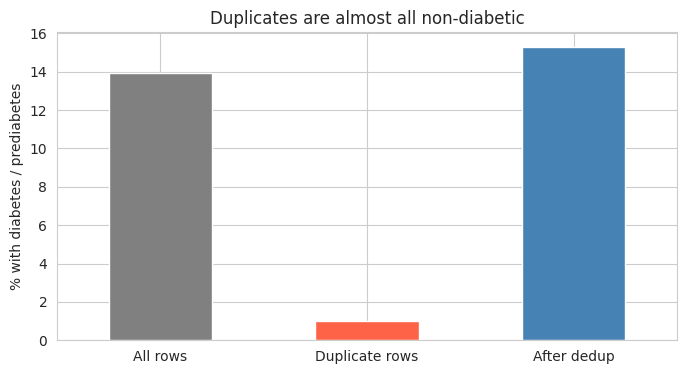

In [10]:
print(df[dup][["HighBP", "HighChol", "GenHlth", "BMI", "Age"]].mean().round(2))

rates = pd.Series({
    "All rows": df[target].mean() * 100,
    "Duplicate rows": df[dup][target].mean() * 100,
    "After dedup": df_nodup[target].mean() * 100,
})
rates.plot(kind="bar", color=["grey", "tomato", "steelblue"])
plt.title("Duplicates are almost all non-diabetic")
plt.ylabel("% with diabetes / prediabetes")
plt.xticks(rotation=0)
plt.show()

In [11]:
q1, q3 = df["BMI"].quantile(0.25), df["BMI"].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("IQR fences:", low, "to", high)
print("BMI outliers (IQR rule):", ((df["BMI"] < low) | (df["BMI"] > high)).sum())
print("BMI >= 50:", (df["BMI"] >= 50).sum())
print("BMI >= 80:", (df["BMI"] >= 80).sum())
print("BMI > 70: ", (df["BMI"] > 70).sum())
print("BMI < 15: ", (df["BMI"] < 15).sum())
print()
print("Skewness:")
print(df[["BMI", "MentHlth", "PhysHlth"]].skew().round(2))

IQR fences: 13.5 to 41.5
BMI outliers (IQR rule): 9847
BMI >= 50: 2547
BMI >= 80: 281
BMI > 70:  584
BMI < 15:  68

Skewness:
BMI         2.12
MentHlth    2.72
PhysHlth    2.21
dtype: float64


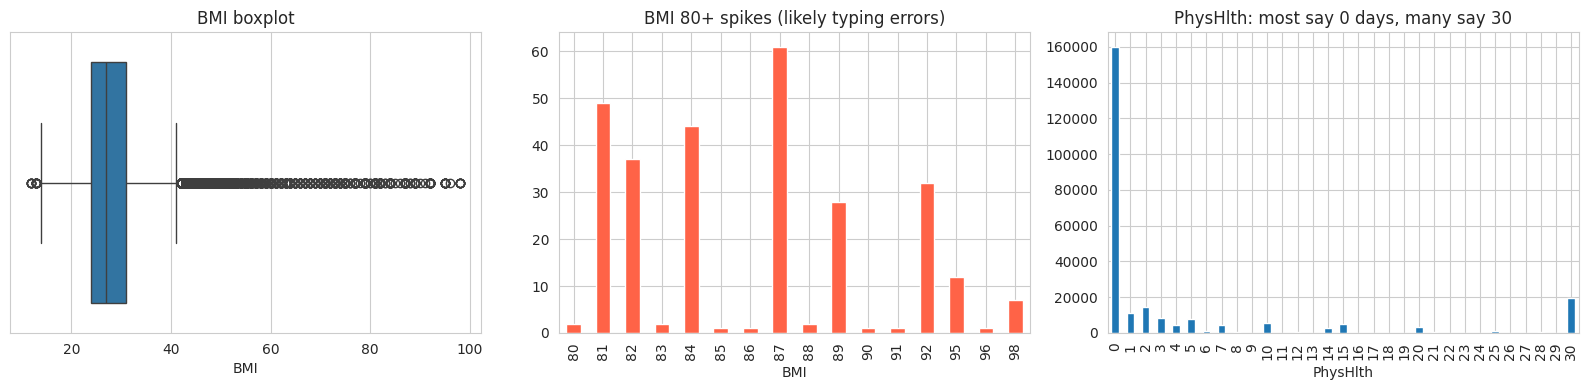

MentHlth: 69.3% are 0, 4.8% are 30
PhysHlth: 63.1% are 0, 7.6% are 30


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x=df["BMI"], ax=axes[0])
axes[0].set_title("BMI boxplot")
df[df["BMI"] >= 80]["BMI"].value_counts().sort_index().plot(kind="bar", color="tomato", ax=axes[1])
axes[1].set_title("BMI 80+ spikes (likely typing errors)")
df["PhysHlth"].value_counts().sort_index().plot(kind="bar", ax=axes[2])
axes[2].set_title("PhysHlth: most say 0 days, many say 30")
plt.tight_layout()
plt.show()

for col in ["MentHlth", "PhysHlth"]:
    print(f"{col}: {(df[col]==0).mean()*100:.1f}% are 0, {(df[col]==30).mean()*100:.1f}% are 30")

In [13]:
checks = {
    "HighChol=1 but CholCheck=0": ((df["HighChol"] == 1) & (df["CholCheck"] == 0)).sum(),
    "GenHlth=1 (excellent) but PhysHlth=30": ((df["GenHlth"] == 1) & (df["PhysHlth"] == 30)).sum(),
    "PhysHlth=30 but DiffWalk=0": ((df["PhysHlth"] == 30) & (df["DiffWalk"] == 0)).sum(),
    "Age 18-24 with diabetes": ((df["Age"] == 1) & (df[target] == 1)).sum(),
    "No health coverage": (df["AnyHealthcare"] == 0).sum(),
}
pd.Series(checks, name="Rows")

,Rows
HighChol=1 but CholCheck=0,1981
GenHlth=1 (excellent) but PhysHlth=30,416
PhysHlth=30 but DiffWalk=0,6719
Age 18-24 with diabetes,78
No health coverage,12417


In [14]:
clean = df.copy()

clean = clean.drop_duplicates()

clean["BMI"] = clean["BMI"].clip(upper=70)

bins, labels = [-1, 0, 13, 30], [0, 1, 2]
clean["MentHlth_bin"] = pd.cut(clean["MentHlth"], bins=bins, labels=labels).astype(int)
clean["PhysHlth_bin"] = pd.cut(clean["PhysHlth"], bins=bins, labels=labels).astype(int)

clean["Education"] = clean["Education"].replace(1, 2)

clean = clean.astype("int16")

print("Clean shape:", clean.shape)
print("Positive rate:", round(clean[target].mean() * 100, 1), "%")

Clean shape: (229474, 24)
Positive rate: 15.3 %
